### Notebook 2: Blocked split and YOLO11n training
Requires pork_rasher_v4.zip in Google Drive and a T4 GPU runtime.

#### 0. Setup

In [1]:
# Install Ultralytics
%pip install -q ultralytics

In [2]:
# Mount Google Drive, set paths and unzip the dataset
import zipfile
from pathlib import Path

ZIP_PATH = Path("/content/drive/MyDrive/pork_rasher_v4.zip")
DATA_DIR = Path("/content/pork_rasher")             # unzipped dataset
SPLITS_DIR = Path("/content/splits")                # output folder for the two splits
RUNS_DIR = Path("/content/drive/MyDrive/pork_runs") # results folder in Google Drive

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

if not (DATA_DIR / "data.yaml").exists():
    print("unzipping...")
    zipfile.ZipFile(ZIP_PATH).extractall(DATA_DIR)
assert (DATA_DIR / "data.yaml").exists(), "can't find data.yaml"
(RUNS_DIR / "figures").mkdir(parents=True, exist_ok=True)

Mounted at /content/drive
unzipping...


##### Settings

In [3]:
# Training and split settings
import torch

MODEL = "yolo11n.pt"   # YOLO11 nano, COCO pre-trained
EPOCHS = 50            # training epochs
IMGSZ = 640            # input image size
BATCH = 16
BLOCK_SIZE = 200       # frames per block
BUFFER = 15            # min frame gap between train and valid/test
SEED = 0               # random seed
TARGET = {"train": 0.70, "valid": 0.15, "test": 0.15}

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (training will be very slow)")

GPU: Tesla T4


#### 1. Load labels

In [4]:
# Read images and labels into tables
import re
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from PIL import Image

SPLITS = ["train", "valid", "test"]

with open(DATA_DIR / "data.yaml") as f:
    CLASS_NAMES = yaml.safe_load(f)["names"]

image_rows = []
box_rows = []
for split in SPLITS:
    img_files = sorted(p for p in (DATA_DIR / split / "images").iterdir()
                       if p.suffix.lower() in [".jpg", ".jpeg", ".png"])
    for img_path in img_files:
        label_path = DATA_DIR / split / "labels" / (img_path.stem + ".txt")
        lines = label_path.read_text().splitlines() if label_path.exists() else []
        lines = [l.split() for l in lines if len(l.split()) == 5]
        for l in lines:
            box_rows.append({"image": img_path.name, "class_name": CLASS_NAMES[int(l[0])]})
        frame = re.search(r"frame_with_red_(\d+)", img_path.name)
        image_rows.append({"split": split, "image": img_path.name, "path": img_path, "label_path": label_path,
                           "n_boxes": len(lines),
                           "source_stem": img_path.name.split(".rf.")[0],
                           "frame_no": int(frame.group(1)) if frame else None})

images = pd.DataFrame(image_rows)
boxes = pd.DataFrame(box_rows)
print(len(images), "images,", len(boxes), "boxes,", images.source_stem.nunique(), "unique original images")

3549 images, 3123 boxes, 1272 unique original images


#### 2. Leakage examples

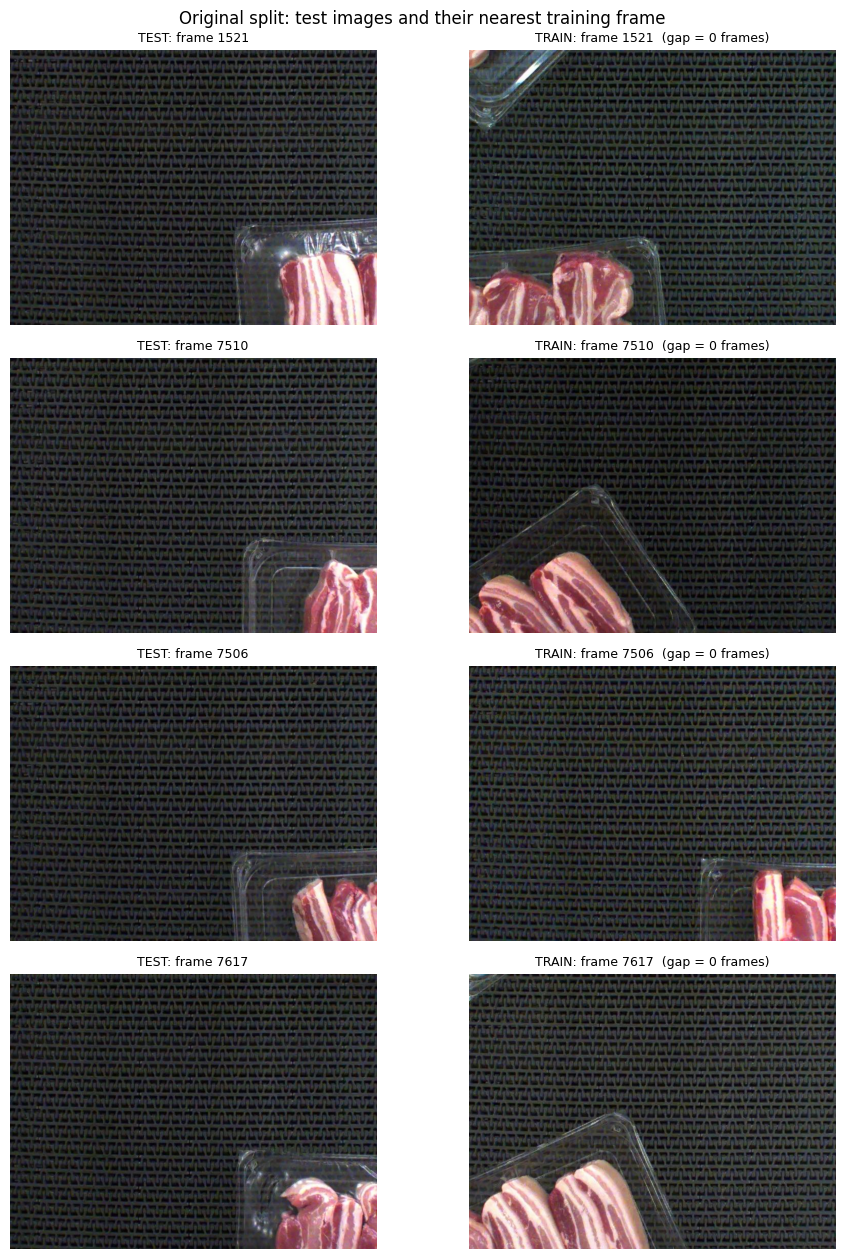

In [5]:
# Plot the 4 test images with the smallest frame gap to a training image
train_imgs = images[images.split == "train"].dropna(subset=["frame_no"]).drop_duplicates("source_stem")
test_imgs = images[images.split == "test"].dropna(subset=["frame_no"]).copy()

# nearest training frame for each test image
train_frames = train_imgs.frame_no.to_numpy()
closest = [np.argmin(np.abs(train_frames - f)) for f in test_imgs.frame_no]
test_imgs["train_path"] = train_imgs.path.to_numpy()[closest]
test_imgs["train_frame"] = train_frames[closest]
test_imgs["gap"] = (test_imgs.frame_no - test_imgs.train_frame).abs()

pairs = test_imgs.sort_values("gap").head(4)   # 4 smallest gaps
fig, axes = plt.subplots(len(pairs), 2, figsize=(10, 3.2 * len(pairs)), squeeze=False)
for row, (_, r) in zip(axes, pairs.iterrows()):
    row[0].imshow(Image.open(r.path))
    row[0].set_title(f"TEST: frame {int(r.frame_no)}", fontsize=9)
    row[1].imshow(Image.open(r.train_path))
    row[1].set_title(f"TRAIN: frame {int(r.train_frame)}  (gap = {int(r.gap)} frames)", fontsize=9)
    row[0].axis("off")
    row[1].axis("off")
plt.suptitle("Original split: test images and their nearest training frame")
plt.tight_layout()
plt.savefig(RUNS_DIR / "figures" / "leakage_examples.png", dpi=150)
plt.show()

#### 3. Splits

##### Unique images and frame blocks

In [6]:
# one row per original image
uniq = images.drop_duplicates("source_stem").reset_index(drop=True).copy()
uniq["original_split"] = uniq["split"]

# set of classes per image (empty set = no defects)
classes_per_image = boxes.groupby("image")["class_name"].agg(set)
uniq["classes"] = uniq["image"].map(classes_per_image)
uniq["classes"] = uniq["classes"].apply(lambda s: s if isinstance(s, set) else set())

uniq["block"] = (uniq["frame_no"] // BLOCK_SIZE).astype("Int64")   # block index

##### Blocked split

In [7]:
# Try 500 random block assignments, keep the best-balanced one, then apply the buffer
def assign_blocks(seed):
    # assign shuffled blocks to test, then valid, then train
    rng = np.random.default_rng(seed)
    blocks = uniq["block"].dropna().unique().to_numpy(dtype="int64")
    rng.shuffle(blocks)
    block_sizes = uniq.groupby("block").size()
    total = block_sizes.sum()
    done = 0
    block_split = {}
    for b in blocks:
        share_so_far = done / total
        if share_so_far < TARGET["test"]:
            block_split[b] = "test"
        elif share_so_far < TARGET["test"] + TARGET["valid"]:
            block_split[b] = "valid"
        else:
            block_split[b] = "train"
        done += block_sizes[b]
    return uniq["block"].map(block_split).fillna("train")   # no frame number -> train


def split_score(assignment):
    # distance of each class's valid/test share from the target (lower = better)
    score = 0.0
    for c in CLASS_NAMES + ["(no defect)"]:
        if c == "(no defect)":
            has_c = uniq["classes"].apply(len) == 0
        else:
            has_c = uniq["classes"].apply(lambda s: c in s)
        n = has_c.sum()
        if n == 0:
            continue
        for s in ["valid", "test"]:
            share = (has_c & (assignment == s)).sum() / n
            score += abs(share - TARGET[s])
            if n >= 3 and share == 0:
                score += 1.0   # penalty: class missing from valid or test
    return score


scores = {seed: split_score(assign_blocks(seed)) for seed in range(500)}
best_seed = min(scores, key=scores.get)
uniq["blocked_split"] = assign_blocks(best_seed)
print("best seed:", best_seed, " score:", round(scores[best_seed], 3))

# drop training images within BUFFER frames of a valid/test image
held_out_frames = uniq.loc[uniq.blocked_split != "train", "frame_no"].dropna().to_numpy()


def too_close(f):
    if pd.isna(f):
        return False
    return np.abs(held_out_frames - f).min() <= BUFFER


drop = (uniq.blocked_split == "train") & uniq.frame_no.apply(too_close)
uniq.loc[drop, "blocked_split"] = "dropped (buffer)"
print("dropped", drop.sum(), "training images that were too close to a valid/test image")

best seed: 137  score: 0.933
dropped 27 training images that were too close to a valid/test image


##### Split check

In [8]:
# Class counts per split and frame-gap check for both split schemes
def class_counts(df):
    counts = {c: df["classes"].apply(lambda s: c in s).sum() for c in CLASS_NAMES}
    counts["(no defect)"] = (df["classes"].apply(len) == 0).sum()
    return counts


rows = []
for scheme in ["original_split", "blocked_split"]:
    for s in SPLITS:
        part = uniq[uniq[scheme] == s]
        rows.append({"scheme": scheme.replace("_split", ""), "split": s, "images": len(part), **class_counts(part)})
split_table = pd.DataFrame(rows).set_index(["scheme", "split"])
display(split_table)


def leakage_stats(scheme):
    train_f = uniq.loc[uniq[scheme] == "train", "frame_no"].dropna().to_numpy()
    test_f = uniq.loc[uniq[scheme] == "test", "frame_no"].dropna().to_numpy()
    gaps = np.array([np.abs(train_f - f).min() for f in test_f])
    return {"scheme": scheme.replace("_split", ""), "test_images": len(test_f),
            "median_gap_frames": float(np.median(gaps)),
            "pct_within_5_frames": round(100 * float(np.mean(gaps <= 5)), 1),
            "min_gap_frames": int(gaps.min())}


leak_table = pd.DataFrame([leakage_stats("original_split"), leakage_stats("blocked_split")]).set_index("scheme")
display(leak_table)

# save split assignment and tables
uniq[["image", "source_stem", "frame_no", "original_split", "blocked_split"]].to_csv(RUNS_DIR / "split_assignment.csv", index=False)
split_table.to_csv(RUNS_DIR / "split_class_counts.csv")
leak_table.to_csv(RUNS_DIR / "split_leakage.csv")

images  loose-meat  packaging-error  twisted-meat  unsealed  \
scheme   split                                                                
original train    1085          22              501            23       340   
         valid     112           3               23             3        74   
         test       75           2               14             4        47   
blocked  train     844          15              369            21       298   
         valid     204           5               79             5        64   
         test      197           4               74             4        92   

                wrinkle  (no defect)  
scheme   split                        
original train        6          219  
         valid        0           13  
         test         0           11  
blocked  train        0          162  
         valid        5           50  
         test         1           29

,test_images,median_gap_frames,pct_within_5_frames,min_gap_frames
scheme,,,,
original,75,3.0,65.3,1
blocked,197,102.0,0.0,16


##### YOLO folders

In [9]:
# Copy images and labels into YOLO folders and write a data.yaml for each split scheme
def write_yolo_split(scheme, name):
    root = SPLITS_DIR / name
    if root.exists():
        shutil.rmtree(root)
    for s in SPLITS:
        (root / s / "images").mkdir(parents=True)
        (root / s / "labels").mkdir(parents=True)
        for _, r in uniq[uniq[scheme] == s].iterrows():
            shutil.copy(r.path, root / s / "images" / r.path.name)
            if r.label_path.exists():
                shutil.copy(r.label_path, root / s / "labels" / r.label_path.name)
            else:
                (root / s / "labels" / (r.path.stem + ".txt")).write_text("")   # empty label file
    yaml_path = root / "data.yaml"
    yaml_path.write_text(yaml.safe_dump({"path": str(root), "train": "train/images", "val": "valid/images",
                                         "test": "test/images", "names": dict(enumerate(CLASS_NAMES))},
                                        sort_keys=False))
    print(name, {s: len(list((root / s / "images").iterdir())) for s in SPLITS})
    return yaml_path


DATA_YAML = {"original": write_yolo_split("original_split", "original"),
             "blocked": write_yolo_split("blocked_split", "blocked")}

original {'train': 1085, 'valid': 112, 'test': 75}
blocked {'train': 844, 'valid': 204, 'test': 197}


#### 4. Training

In [10]:
# Train YOLO11n on each split (skipped if best.pt already exists)
# resume an interrupted run: YOLO(str(RUNS_DIR / name / "weights" / "last.pt")).train(resume=True)
from ultralytics import YOLO

BEST = {}
for name in ["original", "blocked"]:
    best = RUNS_DIR / name / "weights" / "best.pt"
    if best.exists():
        print(name, "already trained, skipping")
    else:
        print("training on the", name, "split")
        YOLO(MODEL).train(data=str(DATA_YAML[name]), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
                          device=DEVICE, seed=SEED, deterministic=True,
                          project=str(RUNS_DIR), name=name, exist_ok=True, plots=True, verbose=False)
    BEST[name] = best

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
original already trained, skipping
blocked already trained, skipping


##### Training curves

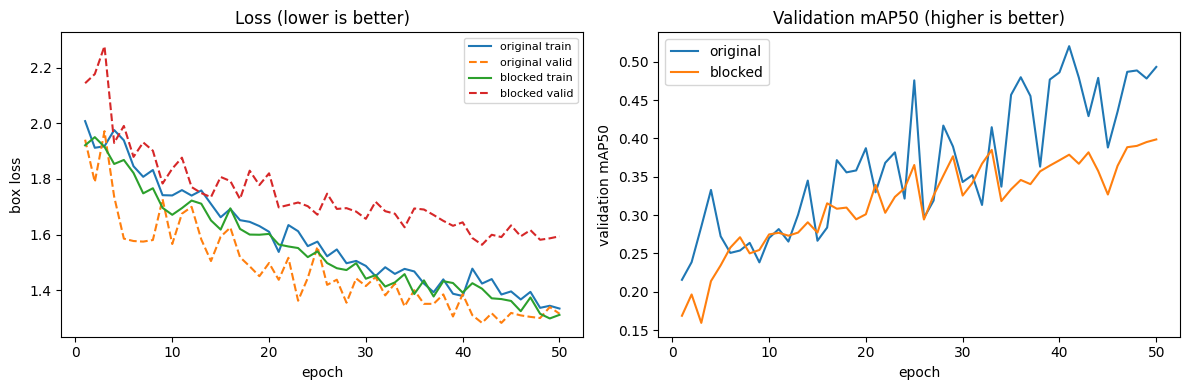

In [11]:
# Box loss and validation mAP50 per epoch
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in ["original", "blocked"]:
    r = pd.read_csv(RUNS_DIR / name / "results.csv")
    r.columns = r.columns.str.strip()
    axes[0].plot(r["epoch"], r["train/box_loss"], label=name + " train")
    axes[0].plot(r["epoch"], r["val/box_loss"], "--", label=name + " valid")
    axes[1].plot(r["epoch"], r["metrics/mAP50(B)"], label=name)
axes[0].set(xlabel="epoch", ylabel="box loss", title="Loss (lower is better)")
axes[1].set(xlabel="epoch", ylabel="validation mAP50", title="Validation mAP50 (higher is better)")
axes[0].legend(fontsize=8)
axes[1].legend()
plt.tight_layout()
plt.savefig(RUNS_DIR / "figures" / "training_curves.png", dpi=150)
plt.show()

#### 5. Test results

In [12]:
# Test-set precision, recall, mAP50, mAP50-95 and inference time for each split
summary_rows = []
per_class = {}
for name in ["original", "blocked"]:
    m = YOLO(str(BEST[name])).val(data=str(DATA_YAML[name]), split="test", imgsz=IMGSZ, batch=BATCH,
                                  device=DEVICE, project=str(RUNS_DIR), name=name + "_test",
                                  exist_ok=True, plots=True, verbose=False)
    n_test = len(list((SPLITS_DIR / name / "test" / "images").iterdir()))
    summary_rows.append({"split": name, "test_images": n_test, "precision": m.box.mp, "recall": m.box.mr,
                         "mAP50": m.box.map50, "mAP50_95": m.box.map,
                         "inference_ms_per_image": m.speed["inference"]})
    per_class[name] = {CLASS_NAMES[c]: ap for c, ap in zip(m.box.ap_class_index, m.box.ap50)}

results = pd.DataFrame(summary_rows).set_index("split").round(3)
per_class_table = pd.DataFrame(per_class).reindex(CLASS_NAMES).round(3)
per_class_table.index.name = "mAP50 per class"
display(results)
display(per_class_table)   # NaN = class not in that test set
results.to_csv(RUNS_DIR / "test_results.csv")
per_class_table.to_csv(RUNS_DIR / "test_results_per_class.csv")

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1109.5±350.9 MB/s, size: 66.4 KB)
val: Scanning /content/splits/original/test/labels... 75 images, 11 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 75/75 2.2Kit/s 0.0s
val: New cache created: /content/splits/original/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.6it/s 3.1s
                   all         75         74      0.725      0.371      0.427      0.237
Speed: 5.0ms preprocess, 16.6ms inference, 0.0ms loss, 3.0ms postprocess per image
Results saved to /content/drive/MyDrive/pork_runs/original_test
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅

,test_images,precision,recall,mAP50,mAP50_95,inference_ms_per_image
split,,,,,,
original,75,0.725,0.371,0.427,0.237,16.599
blocked,197,0.564,0.367,0.459,0.230,4.287


,original,blocked
mAP50 per class,,
loose-meat,0.401,0.361
packaging-error,0.300,0.626
twisted-meat,0.122,0.388
unsealed,0.883,0.919
wrinkle,NaN,0.000


##### Confusion matrices

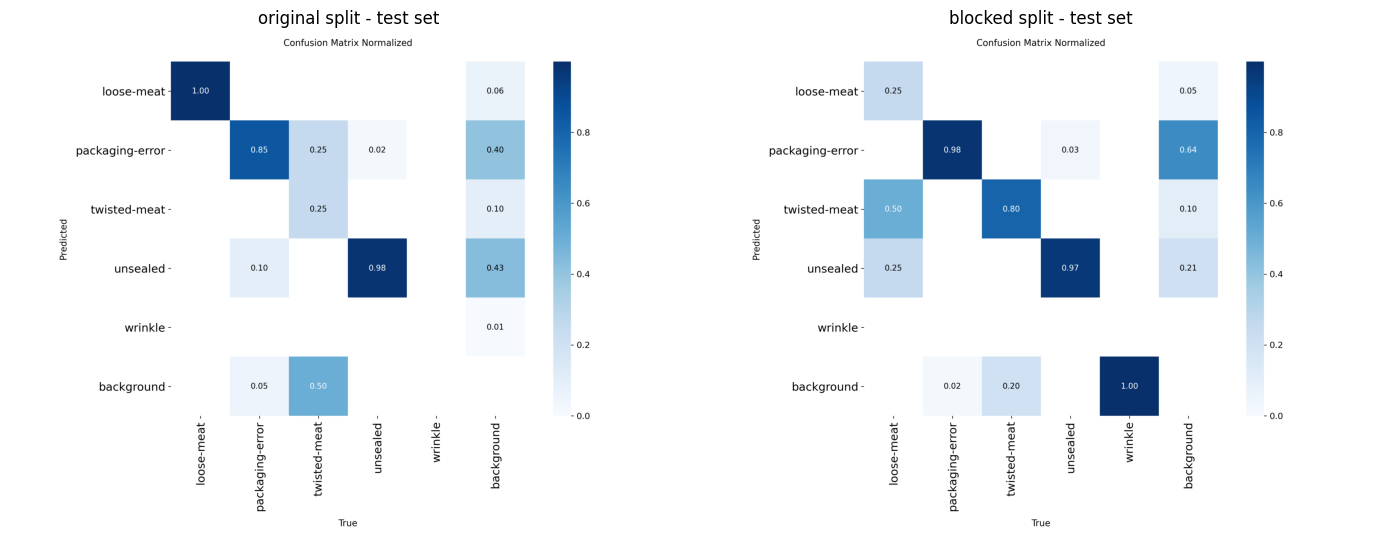

In [13]:
# Normalised confusion matrices on the test set
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, name in zip(axes, ["original", "blocked"]):
    p = RUNS_DIR / (name + "_test") / "confusion_matrix_normalized.png"
    if p.exists():
        ax.imshow(Image.open(p))
    ax.set_title(name + " split - test set")
    ax.axis("off")
plt.tight_layout()
plt.show()